In [1]:
import pandas as pd
import numpy as np
import re
from bs4 import BeautifulSoup
from html import unescape

# Load the raw scraped dataset
df = pd.read_csv("raw_job_market_data.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1021, 17)


,Job_ID,Job_Title,Company,Location,Job_Level,Job_Industry,Employment_Type,Job_Description,Job_Excerpt,Publication_Date,Salary_Min,Salary_Max,Salary_Currency,Salary_Period,Job_URL,Source,Collected_Using
0,151870,Account Executive Mid-Market - Italy,Alma,Italy,Director,Sales,Full-Time,"About Alma At Alma, we believe sustainable com...","About Alma At Alma, we believe sustainable com...",2026-09-26 11:30:15+00:00,68000.0,86000.0,EUR,yearly,https://jobicy.com/jobs/151870-account-executi...,Jobicy,all_jobs
1,152598,"Junior Web Builder (Fully Remote, PH-Based Onl...",Luxury Presence,Philippines,Senior,"Web, UI & UX Design",Contract,Luxury Presence is building the AI growth plat...,Luxury Presence is building the AI growth plat...,2026-09-26 11:25:10+00:00,500.0,500.0,USD,monthly,https://jobicy.com/jobs/152598-junior-web-buil...,Jobicy,all_jobs
2,151608,ERP System Administrator (Acumatica),Alimentiv,Canada,Senior,DevOps & Infrastructure,Full-Time,The ERP System Administrator is an individual ...,The ERP System Administrator is an individual ...,2026-09-26 11:25:09+00:00,78000.0,130000.0,CAD,yearly,https://jobicy.com/jobs/151608-erp-system-admi...,Jobicy,all_jobs
3,144385,RAGBRAI Ride Operations,Gannett,USA,Any,Product & Operations,Full-Time,"USA TODAY Co., Inc. is a diversified media com...","USA TODAY Co., Inc. is a diversified media com...",2026-09-26 11:25:07+00:00,45000.0,50000.0,USD,yearly,https://jobicy.com/jobs/144385-ragbrai-ride-op...,Jobicy,all_jobs
4,152475,Account Executive - EMEA Specialist,Samsara,UK,Director,Sales,Full-Time,Who we are Samsara (NYSE: IOT) is the pioneer ...,Who we are Samsara (NYSE: IOT) is the pioneer ...,2026-09-26 11:20:06+00:00,NaN,NaN,NaN,NaN,https://jobicy.com/jobs/152475-account-executi...,Jobicy,all_jobs


In [2]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate Job IDs:", df["Job_ID"].duplicated().sum())

Number of rows: 1021
Number of columns: 17

Column names:
['Job_ID', 'Job_Title', 'Company', 'Location', 'Job_Level', 'Job_Industry', 'Employment_Type', 'Job_Description', 'Job_Excerpt', 'Publication_Date', 'Salary_Min', 'Salary_Max', 'Salary_Currency', 'Salary_Period', 'Job_URL', 'Source', 'Collected_Using']

Missing values:


Job_ID                0
Job_Title             0
Company               0
Location              0
Job_Level             0
Job_Industry          0
Employment_Type       0
Job_Description       0
Job_Excerpt           0
Publication_Date      0
Salary_Min          513
Salary_Max          522
Salary_Currency     514
Salary_Period       518
Job_URL               0
Source                0
Collected_Using       0
dtype: int64


Duplicate rows: 0

Duplicate Job IDs: 0


In [3]:
def clean_text(value):
    if pd.isna(value):
        return ""
    
    text = unescape(str(value))
    text = BeautifulSoup(text, "html.parser").get_text(" ", strip=True)
    text = re.sub(r"\s+", " ", text)
    
    return text.strip()


text_columns = [
    "Job_Title",
    "Company",
    "Location",
    "Job_Level",
    "Job_Industry",
    "Employment_Type",
    "Job_Description",
    "Job_Excerpt"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].apply(clean_text)

print("Text cleaning completed.")

Text cleaning completed.


In [4]:
before = len(df)

df = df.drop_duplicates(subset="Job_ID").copy()

after = len(df)

print("Records before removing duplicate Job IDs:", before)
print("Records after removing duplicate Job IDs:", after)
print("Duplicates removed:", before - after)

Records before removing duplicate Job IDs: 1021
Records after removing duplicate Job IDs: 1021
Duplicates removed: 0


In [5]:
categorical_columns = [
    "Job_Title",
    "Company",
    "Location",
    "Job_Level",
    "Job_Industry",
    "Employment_Type"
]

for col in categorical_columns:
    df[col] = df[col].replace("", np.nan)
    df[col] = df[col].fillna("Unknown")

print("Missing categorical values handled.")

display(df[categorical_columns].head())

Missing categorical values handled.


,Job_Title,Company,Location,Job_Level,Job_Industry,Employment_Type
0,Account Executive Mid-Market - Italy,Alma,Italy,Director,Sales,Full-Time
1,"Junior Web Builder (Fully Remote, PH-Based Onl...",Luxury Presence,Philippines,Senior,"Web, UI & UX Design",Contract
2,ERP System Administrator (Acumatica),Alimentiv,Canada,Senior,DevOps & Infrastructure,Full-Time
3,RAGBRAI Ride Operations,Gannett,USA,Any,Product & Operations,Full-Time
4,Account Executive - EMEA Specialist,Samsara,UK,Director,Sales,Full-Time


In [6]:
salary_columns = [
    "Salary_Min",
    "Salary_Max"
]

for col in salary_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Salary columns converted to numeric.")

display(df[salary_columns].head())

Salary columns converted to numeric.


,Salary_Min,Salary_Max
0,68000.0,86000.0
1,500.0,500.0
2,78000.0,130000.0
3,45000.0,50000.0
4,NaN,NaN


In [7]:
df["Salary_Mid"] = df[
    ["Salary_Min", "Salary_Max"]
].mean(axis=1)

df["Salary_Available"] = (
    df[["Salary_Min", "Salary_Max"]]
    .notna()
    .any(axis=1)
    .astype(int)
)

display(
    df[
        [
            "Salary_Min",
            "Salary_Max",
            "Salary_Mid",
            "Salary_Available"
        ]
    ].head(10)
)

,Salary_Min,Salary_Max,Salary_Mid,Salary_Available
0,68000.0,86000.0,77000.0,1
1,500.0,500.0,500.0,1
2,78000.0,130000.0,104000.0,1
3,45000.0,50000.0,47500.0,1
4,NaN,NaN,NaN,0
5,NaN,NaN,NaN,0
6,NaN,NaN,NaN,0
7,69000.0,101200.0,85100.0,1
8,NaN,NaN,NaN,0
9,NaN,NaN,NaN,0


In [8]:
def normalize_salary_period(value):
    value = str(value).lower().strip()

    if value in ["year", "yearly", "annual", "annually"]:
        return "Yearly"
    
    elif value in ["month", "monthly"]:
        return "Monthly"
    
    elif value in ["week", "weekly"]:
        return "Weekly"
    
    elif value in ["day", "daily"]:
        return "Daily"
    
    elif value in ["hour", "hourly"]:
        return "Hourly"
    
    else:
        return "Unknown"


df["Salary_Period_Normalized"] = df[
    "Salary_Period"
].apply(normalize_salary_period)

print(df["Salary_Period_Normalized"].value_counts())

Salary_Period_Normalized
Unknown    518
Yearly     489
Monthly     10
Hourly       4
Name: count, dtype: int64


In [9]:
period_multiplier = {
    "Yearly": 1,
    "Monthly": 12,
    "Weekly": 52,
    "Daily": 260,
    "Hourly": 2080
}

df["Annual_Salary_Reported_Currency"] = (
    df["Salary_Mid"] *
    df["Salary_Period_Normalized"].map(period_multiplier)
)

display(
    df[
        [
            "Salary_Mid",
            "Salary_Currency",
            "Salary_Period_Normalized",
            "Annual_Salary_Reported_Currency"
        ]
    ].head(10)
)

,Salary_Mid,Salary_Currency,Salary_Period_Normalized,Annual_Salary_Reported_Currency
0,77000.0,EUR,Yearly,77000.0
1,500.0,USD,Monthly,6000.0
2,104000.0,CAD,Yearly,104000.0
3,47500.0,USD,Yearly,47500.0
4,NaN,NaN,Unknown,NaN
5,NaN,NaN,Unknown,NaN
6,NaN,NaN,Unknown,NaN
7,85100.0,USD,Yearly,85100.0
8,NaN,NaN,Unknown,NaN
9,NaN,NaN,Unknown,NaN


In [10]:
experience_text = (
    df["Job_Title"].fillna("") + " " +
    df["Job_Description"].fillna("")
).str.lower()


def extract_experience_years(text):

    # Example: 2-5 years
    ranges = re.findall(
        r"(\d+(?:\.\d+)?)\s*(?:-|to)\s*"
        r"(\d+(?:\.\d+)?)\s*(?:years?|yrs?)",
        text
    )

    if ranges:
        low, high = map(float, ranges[0])
        return (low + high) / 2

    # Example: 3+ years / 3 years
    match = re.search(
        r"(\d+(?:\.\d+)?)\s*\+?\s*(?:years?|yrs?)",
        text
    )

    if match:
        return float(match.group(1))

    return np.nan


df["Experience_Years_Extracted"] = (
    experience_text.apply(extract_experience_years)
)

display(
    df[
        [
            "Job_Title",
            "Experience_Years_Extracted"
        ]
    ].head(15)
)

,Job_Title,Experience_Years_Extracted
0,Account Executive Mid-Market - Italy,4.0
1,"Junior Web Builder (Fully Remote, PH-Based Onl...",NaN
2,ERP System Administrator (Acumatica),5.0
3,RAGBRAI Ride Operations,52.0
4,Account Executive - EMEA Specialist,5.0
5,Software Architect,10.0
6,"Technical Account Specialist - Storm, Sewer, F...",NaN
7,Business Consultant,NaN
8,"Technical Adoption Specialist, Civil 3D, Frenc...",6.0
9,"Renewals Representative, Account Based, Denmark",NaN


In [11]:
def standardize_job_level(value):

    value = str(value).lower().strip()

    if value == "" or value == "nan":
        return "Unknown"

    if any(word in value for word in [
        "intern",
        "entry",
        "junior",
        "associate"
    ]):
        return "Entry"

    elif any(word in value for word in [
        "mid",
        "intermediate"
    ]):
        return "Mid"

    elif any(word in value for word in [
        "senior",
        "lead",
        "principal",
        "staff"
    ]):
        return "Senior"

    elif any(word in value for word in [
        "director",
        "executive",
        "vp",
        "vice president",
        "c-level"
    ]):
        return "Leadership"

    else:
        return "Other"


df["Job_Level_Standardized"] = (
    df["Job_Level"].apply(standardize_job_level)
)

print(
    df["Job_Level_Standardized"]
    .value_counts()
)

Job_Level_Standardized
Senior        474
Leadership    281
Other         159
Mid            81
Entry          26
Name: count, dtype: int64


In [12]:
def standardize_employment_type(value):

    value = str(value).lower()

    if "full" in value:
        return "Full-time"

    elif "part" in value:
        return "Part-time"

    elif "contract" in value:
        return "Contract"

    elif "intern" in value:
        return "Internship"

    elif "temporary" in value:
        return "Temporary"

    else:
        return "Other"


df["Employment_Type_Standardized"] = (
    df["Employment_Type"]
    .apply(standardize_employment_type)
)

print(
    df["Employment_Type_Standardized"]
    .value_counts()
)

Employment_Type_Standardized
Full-time     970
Contract       37
Part-time       8
Internship      6
Name: count, dtype: int64


In [15]:
skill_patterns = {

    "Python": r"\bpython\b",

    "SQL": r"\bsql\b",

    "Excel": r"\bexcel\b|microsoft excel",

    "Power BI": r"\bpower\s*bi\b",

    "Tableau": r"\btableau\b",

    "Machine Learning": r"\bmachine learning\b",

    "Deep Learning": r"\bdeep learning\b",

    "Artificial Intelligence":
        r"\bartificial intelligence\b|\bai\b",

    "Pandas": r"\bpandas\b",

    "NumPy": r"\bnumpy\b",

    "Scikit-learn":
        r"\bscikit[- ]learn\b|\bsklearn\b",

    "R": r"(?<![a-z])r(?![a-z])",

    "Java": r"\bjava\b",

    "JavaScript": r"\bjavascript\b",

    "React": r"\breact(?:\.js)?\b",

    "Node.js": r"\bnode(?:\.js)?\b",

    "AWS": r"\baws\b|amazon web services",

    "Azure": r"\bazure\b",

    "GCP": r"\bgcp\b|google cloud",

    "Docker": r"\bdocker\b",

    "Kubernetes":
        r"\bkubernetes\b|\bk8s\b",

    "Git": r"\bgit\b|github",

    "Spark":
        r"\bspark\b|apache spark",

    "Hadoop": r"\bhadoop\b",

    "MongoDB": r"\bmongodb\b",

    "PostgreSQL":
        r"\bpostgresql\b|\bpostgres\b",

    "MySQL": r"\bmysql\b",

    "Django": r"\bdjango\b",

    "Flask": r"\bflask\b",

    "TensorFlow": r"\btensorflow\b",

    "PyTorch": r"\bpytorch\b",

    "Statistics":
        r"\bstatistics\b|\bstatistical\b",

    "NLP":
        r"\bnatural language processing\b|\bnlp\b"
}

In [16]:
skill_text = (
    df["Job_Title"].fillna("") + " " +
    df["Job_Description"].fillna("") + " " +
    df["Job_Excerpt"].fillna("")
).str.lower()


for skill, pattern in skill_patterns.items():

    column_name = (
        "Skill_" +
        skill
        .replace("-", "_")
        .replace(".", "")
        .replace(" ", "_")
    )

    df[column_name] = (
        skill_text
        .str.contains(
            pattern,
            regex=True,
            na=False
        )
        .astype(int)
    )


skill_columns = [
    col for col in df.columns
    if col.startswith("Skill_")
]

df["Skill_Count"] = df[skill_columns].sum(axis=1)

print("Number of skill features:", len(skill_columns))

display(
    df[
        ["Job_Title"] +
        skill_columns[:10] +
        ["Skill_Count"]
    ].head()
)

Number of skill features: 33


,Job_Title,Skill_Python,Skill_SQL,Skill_Excel,Skill_Power_BI,Skill_Tableau,Skill_Machine_Learning,Skill_Deep_Learning,Skill_Artificial_Intelligence,Skill_Pandas,Skill_NumPy,Skill_Count
0,Account Executive Mid-Market - Italy,0,0,0,0,0,0,0,0,0,0,0
1,"Junior Web Builder (Fully Remote, PH-Based Onl...",0,0,0,0,0,0,0,1,0,0,1
2,ERP System Administrator (Acumatica),0,0,0,1,0,0,0,0,0,0,1
3,RAGBRAI Ride Operations,0,0,0,0,0,0,0,0,0,0,0
4,Account Executive - EMEA Specialist,0,0,0,0,0,0,0,0,0,0,0


In [17]:
df["Description_Length"] = (
    df["Job_Description"].str.len()
)

df["Word_Count"] = (
    df["Job_Description"]
    .str.split()
    .str.len()
)

display(
    df[
        [
            "Description_Length",
            "Word_Count",
            "Skill_Count"
        ]
    ].describe()
)

,Description_Length,Word_Count,Skill_Count
count,1021.000000,1021.000000,1021.000000
mean,6443.719882,935.988247,3.251714
std,2432.615921,367.492451,2.573300
min,1.000000,1.000000,0.000000
25%,4899.000000,705.000000,1.000000
50%,6001.000000,875.000000,3.000000
75%,7592.000000,1098.000000,5.000000
max,22511.000000,3117.000000,19.000000


In [18]:
print("FINAL DATASET CHECK")
print("=" * 50)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nDuplicate rows:", df.duplicated().sum())

print(
    "Duplicate Job IDs:",
    df["Job_ID"].duplicated().sum()
)

print("\nMissing values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

FINAL DATASET CHECK
Rows: 1021
Columns: 60

Duplicate rows: 0
Duplicate Job IDs: 0

Missing values:


Salary_Max                         522
Annual_Salary_Reported_Currency    518
Salary_Period                      518
Salary_Currency                    514
Salary_Min                         513
Salary_Mid                         511
Experience_Years_Extracted         331
Skill_Git                            0
Skill_Kubernetes                     0
Job_ID                               0
Skill_Spark                          0
Skill_GCP                            0
Skill_Azure                          0
Skill_AWS                            0
Skill_Nodejs                         0
Skill_React                          0
Skill_JavaScript                     0
Skill_Java                           0
Skill_Docker                         0
Skill_MongoDB                        0
dtype: int64

In [19]:
important_columns = [
    "Job_ID",
    "Job_Title",
    "Company",
    "Location",
    "Job_Level_Standardized",
    "Employment_Type_Standardized",
    "Salary_Mid",
    "Salary_Currency",
    "Salary_Period_Normalized",
    "Annual_Salary_Reported_Currency",
    "Experience_Years_Extracted",
    "Skill_Count",
    "Description_Length",
    "Word_Count"
]

display(df[important_columns].head(10))

,Job_ID,Job_Title,Company,Location,Job_Level_Standardized,Employment_Type_Standardized,Salary_Mid,Salary_Currency,Salary_Period_Normalized,Annual_Salary_Reported_Currency,Experience_Years_Extracted,Skill_Count,Description_Length,Word_Count
0,151870,Account Executive Mid-Market - Italy,Alma,Italy,Leadership,Full-time,77000.0,EUR,Yearly,77000.0,4.0,0,5971,918
1,152598,"Junior Web Builder (Fully Remote, PH-Based Onl...",Luxury Presence,Philippines,Senior,Contract,500.0,USD,Monthly,6000.0,NaN,1,6450,955
2,151608,ERP System Administrator (Acumatica),Alimentiv,Canada,Senior,Full-time,104000.0,CAD,Yearly,104000.0,5.0,1,5426,690
3,144385,RAGBRAI Ride Operations,Gannett,USA,Other,Full-time,47500.0,USD,Yearly,47500.0,52.0,0,6315,901
4,152475,Account Executive - EMEA Specialist,Samsara,UK,Leadership,Full-time,NaN,NaN,Unknown,NaN,5.0,0,7763,1173
5,150381,Software Architect,Autodesk,"EMEA, UK",Senior,Full-time,NaN,NaN,Unknown,NaN,10.0,3,9183,1257
6,150370,"Technical Account Specialist - Storm, Sewer, F...",Autodesk,UK,Other,Full-time,NaN,NaN,Unknown,NaN,NaN,1,4649,720
7,149963,Business Consultant,Autodesk,"Denmark, Netherlands, Norway, UK",Other,Full-time,85100.0,USD,Yearly,85100.0,NaN,1,5207,693
8,149313,"Technical Adoption Specialist, Civil 3D, Frenc...",Autodesk,"Poland, Spain",Senior,Full-time,NaN,NaN,Unknown,NaN,6.0,0,3340,498
9,148712,"Renewals Representative, Account Based, Denmark",Autodesk,Denmark,Other,Full-time,NaN,NaN,Unknown,NaN,NaN,0,5706,771


Shape: (1021, 60)

Summary Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Job_ID,1021.0,NaN,NaN,NaN,151573.180215,2278.982309,141971.0,150366.0,152038.0,153357.0,154087.0
Job_Title,1021,959,Senior Software Engineer,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Company,1021,290,Canonical,119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,1021,116,USA,431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job_Level,1021,5,Senior,474,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job_Industry,1021,21,Software Engineering,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment_Type,1021,4,Full-Time,970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job_Description,1021,1006,Canonical is a leading provider of open source...,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job_Excerpt,1021,556,Canonical is a leading provider of open source...,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Publication_Date,1021,937,2026-09-24 18:46:44+00:00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


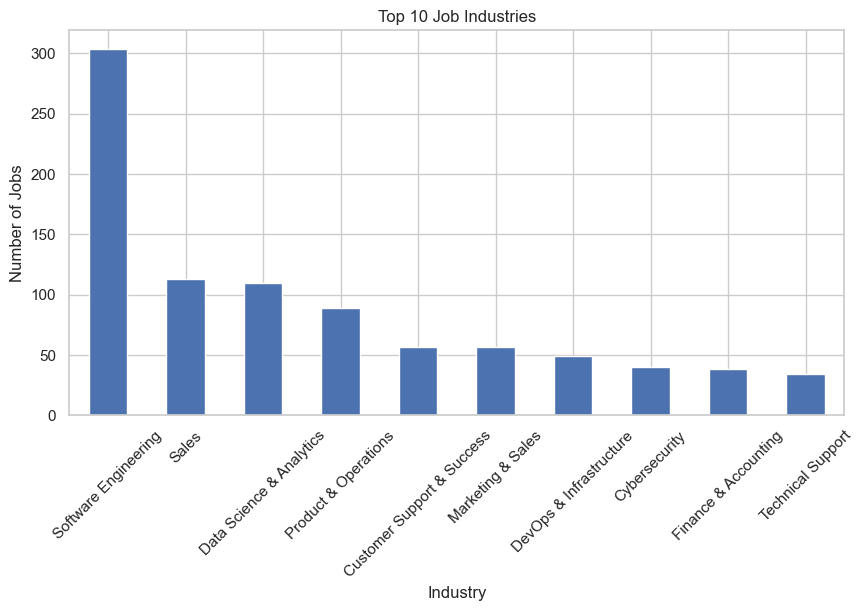

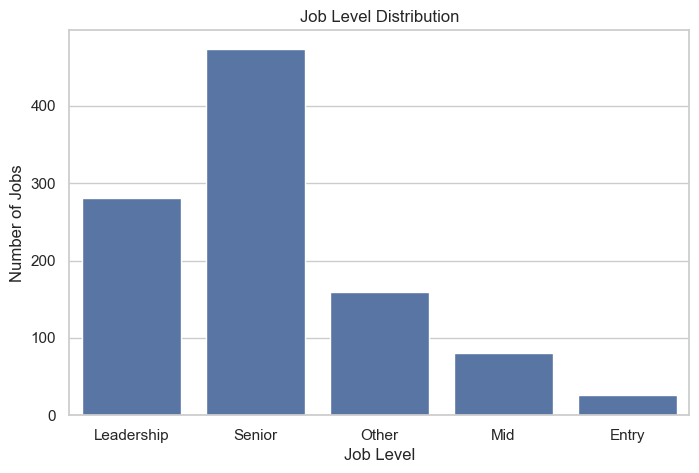

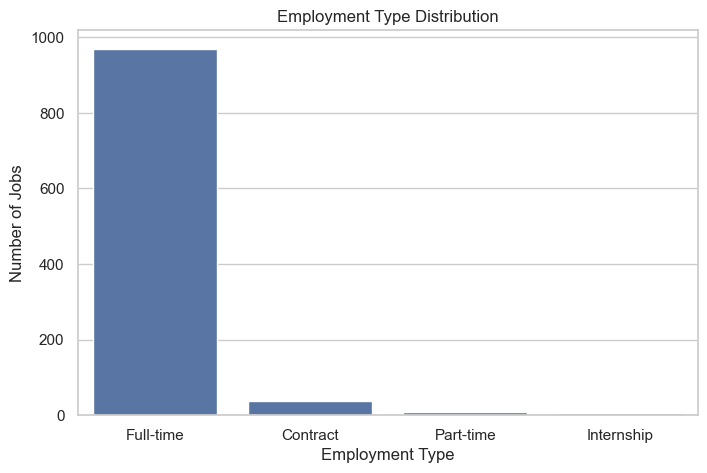

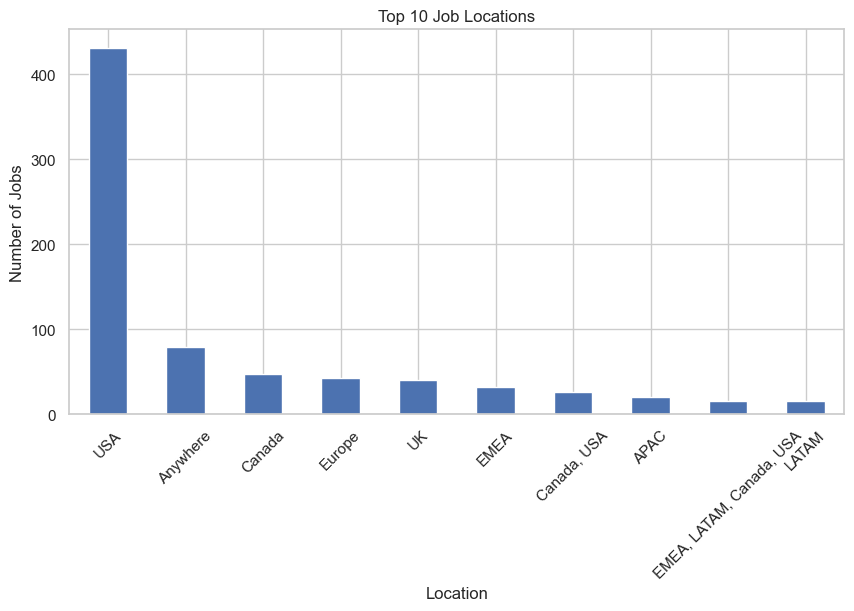

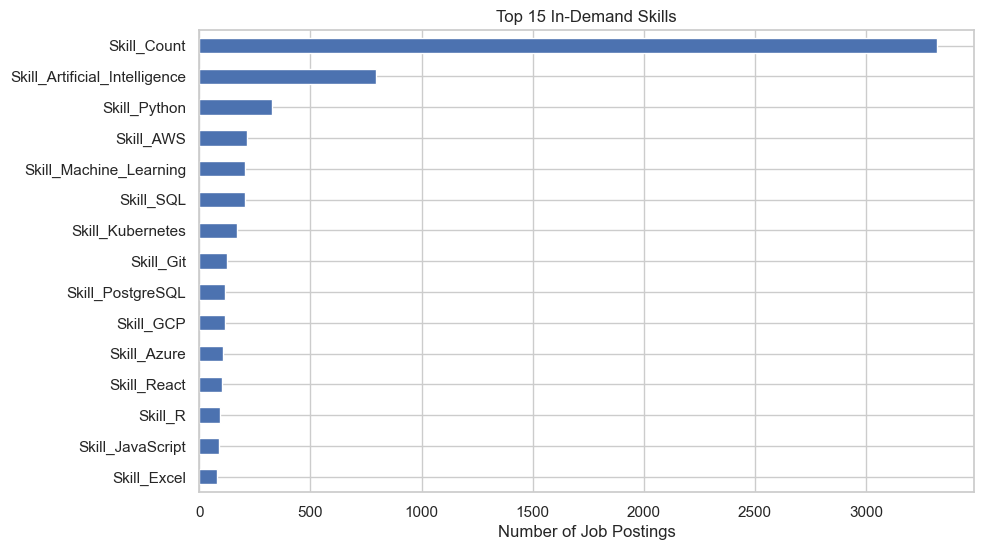

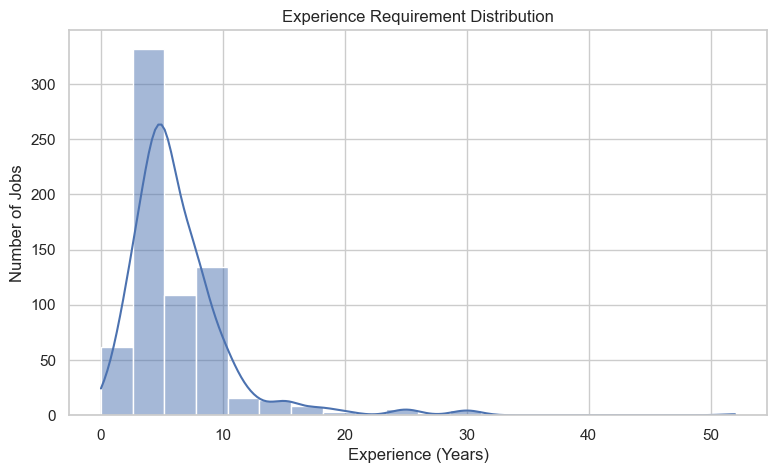

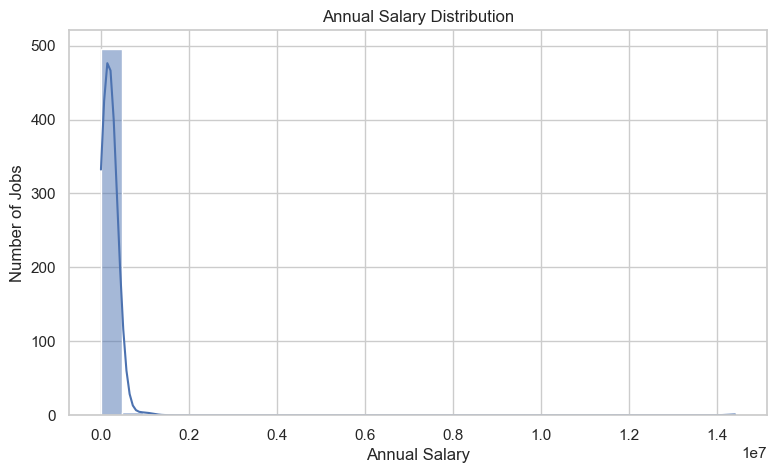

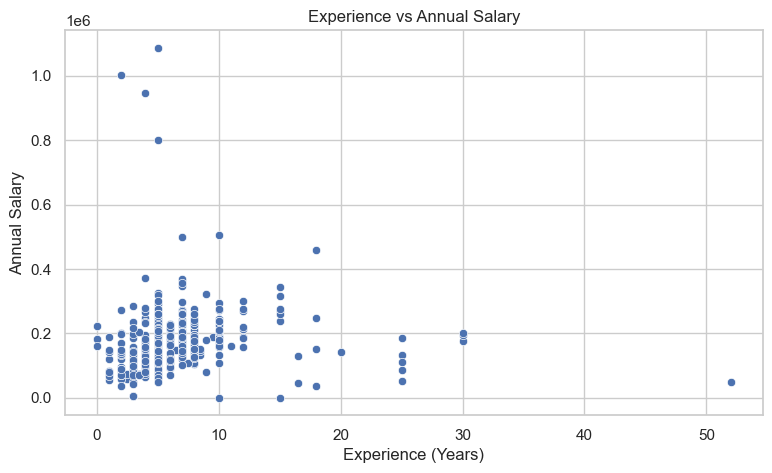

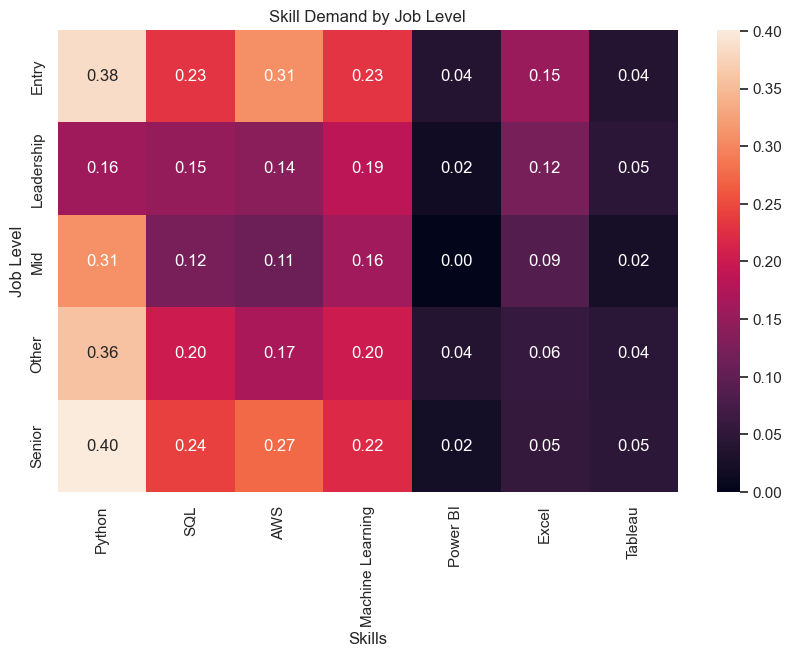

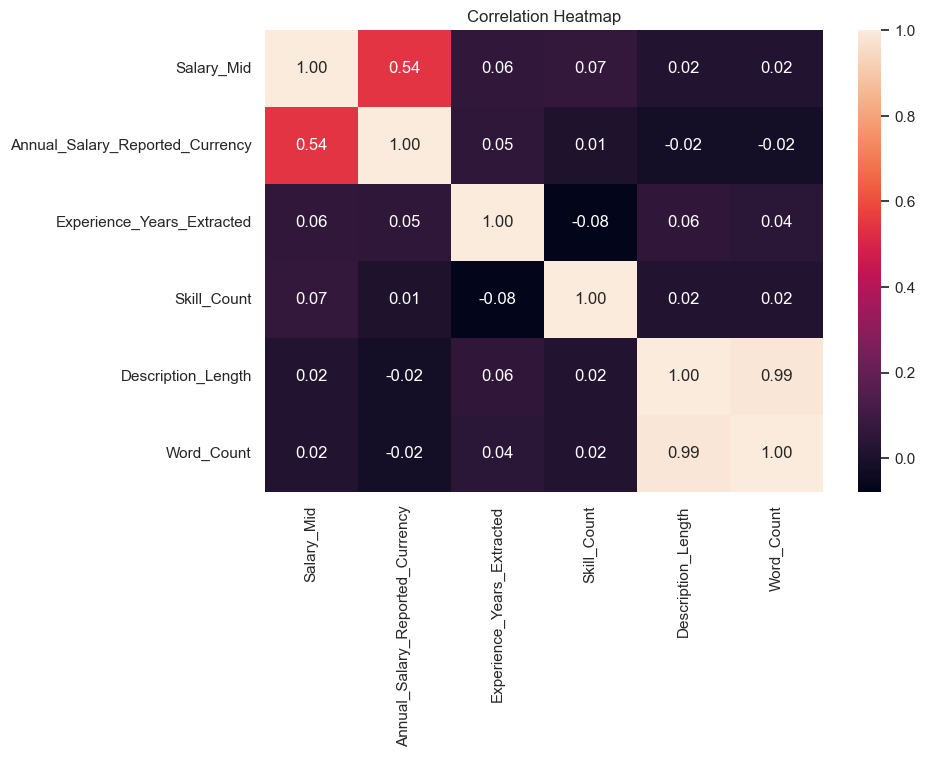

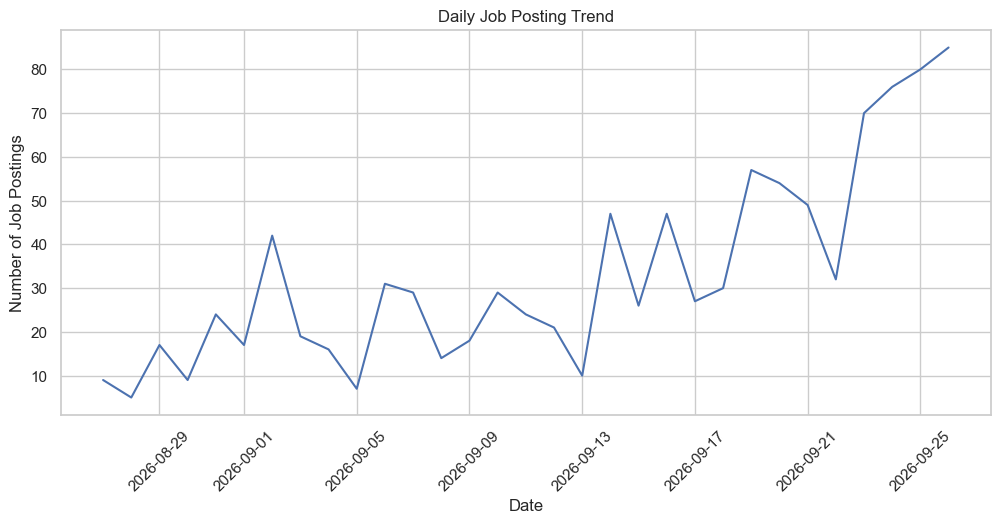

In [22]:
# TASK 3: EDA

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Dataset overview
print("Shape:", df.shape)
print("\nSummary Statistics:")
display(df.describe(include="all").T)

# 2. Top Job Industries
plt.figure(figsize=(10,5))
df["Job_Industry"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Job Industries")
plt.xlabel("Industry")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45)
plt.show()

# 3. Job Level Distribution
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Job_Level_Standardized")
plt.title("Job Level Distribution")
plt.xlabel("Job Level")
plt.ylabel("Number of Jobs")
plt.show()

# 4. Employment Type
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Employment_Type_Standardized")
plt.title("Employment Type Distribution")
plt.xlabel("Employment Type")
plt.ylabel("Number of Jobs")
plt.show()

# 5. Top Locations
plt.figure(figsize=(10,5))
df["Location"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Job Locations")
plt.xlabel("Location")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45)
plt.show()

# 6. Top Skills
skills = [c.replace("Skill_", "") for c in df.columns if c.startswith("Skill_")]
skill_counts = df[[f"Skill_{s}" for s in skills]].sum().sort_values(ascending=False).head(15)

plt.figure(figsize=(10,6))
skill_counts.sort_values().plot(kind="barh")
plt.title("Top 15 In-Demand Skills")
plt.xlabel("Number of Job Postings")
plt.show()

# 7. Experience Distribution
plt.figure(figsize=(9,5))
sns.histplot(df["Experience_Years_Extracted"].dropna(), bins=20, kde=True)
plt.title("Experience Requirement Distribution")
plt.xlabel("Experience (Years)")
plt.ylabel("Number of Jobs")
plt.show()

# 8. Salary Distribution
plt.figure(figsize=(9,5))
sns.histplot(df["Annual_Salary_Reported_Currency"].dropna(), bins=30, kde=True)
plt.title("Annual Salary Distribution")
plt.xlabel("Annual Salary")
plt.ylabel("Number of Jobs")
plt.show()

# 9. Experience vs Salary
plt.figure(figsize=(9,5))
sns.scatterplot(
    data=df,
    x="Experience_Years_Extracted",
    y="Annual_Salary_Reported_Currency"
)
plt.title("Experience vs Annual Salary")
plt.xlabel("Experience (Years)")
plt.ylabel("Annual Salary")
plt.show()

# 10. Skills by Job Level
# 10. Skills by Job Level

key_skills = ["Python", "SQL", "AWS", "Machine_Learning", "Power_BI", "Excel", "Tableau"]

skill_cols = [f"Skill_{s}" for s in key_skills if f"Skill_{s}" in df.columns]

skill_level = df.groupby("Job_Level_Standardized")[skill_cols].mean()

skill_level.columns = [c.replace("Skill_", "").replace("_", " ") for c in skill_level.columns]

plt.figure(figsize=(10,6))
sns.heatmap(skill_level, annot=True, fmt=".2f")
plt.title("Skill Demand by Job Level")
plt.xlabel("Skills")
plt.ylabel("Job Level")
plt.show()

# 11. Correlation Heatmap
corr_cols = [
    "Salary_Mid",
    "Annual_Salary_Reported_Currency",
    "Experience_Years_Extracted",
    "Skill_Count",
    "Description_Length",
    "Word_Count"
]

plt.figure(figsize=(9,6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# 12. Job Posting Trend
df["Publication_Date"] = pd.to_datetime(df["Publication_Date"], errors="coerce")

daily_jobs = df.groupby(df["Publication_Date"].dt.date).size()

plt.figure(figsize=(12,5))
daily_jobs.plot()
plt.title("Daily Job Posting Trend")
plt.xlabel("Date")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)
plt.show()

In [25]:
# CURRENCY CONVERSION

# Exchange rates: 1 unit of currency = USD
# Use one fixed reference date for the project
exchange_rates = {
    "USD": 1.00,
    "EUR": 1.17,
    "GBP": 1.35,
    "CAD": 0.73,
    "AUD": 0.66,
    "NZD": 0.59,
    "SGD": 0.78,
    "INR": 0.011
}

# Convert annual salary to USD
df["Annual_Salary_USD"] = (
    df["Annual_Salary_Reported_Currency"] *
    df["Salary_Currency"].map(exchange_rates)
)

# Check currencies
print("Currencies in dataset:")
print(df["Salary_Currency"].value_counts())

# Check currencies for which conversion rate is missing
missing_rates = df.loc[
    df["Salary_Currency"].notna() &
    ~df["Salary_Currency"].isin(exchange_rates.keys()),
    "Salary_Currency"
].unique()

print("\nCurrencies without conversion rates:", missing_rates)

# Check converted salary
display(
    df[
        [
            "Salary_Currency",
            "Annual_Salary_Reported_Currency",
            "Annual_Salary_USD"
        ]
    ].dropna(subset=["Annual_Salary_USD"]).head(10)
)

Currencies in dataset:
Salary_Currency
USD    418
CAD     35
GBP     25
EUR     21
CZK      2
PLN      2
AUD      1
HUF      1
CNY      1
RON      1
Name: count, dtype: int64

Currencies without conversion rates: ['HUF' 'CZK' 'PLN' 'CNY' 'RON']


,Salary_Currency,Annual_Salary_Reported_Currency,Annual_Salary_USD
0,EUR,77000.0,90090.0
1,USD,6000.0,6000.0
2,CAD,104000.0,75920.0
3,USD,47500.0,47500.0
7,USD,85100.0,85100.0
14,USD,225000.0,225000.0
15,USD,307500.0,307500.0
17,USD,200000.0,200000.0
18,USD,150000.0,150000.0
19,USD,6300.0,6300.0


Total records available for ML: 493
Training records: 394
Testing records: 99

Model training completed.

========== MODEL PERFORMANCE ==========
Model : Random Forest Regressor
RMSE  : 68289.4
MAE   : 51715.36
R²    : 0.2493


,Metric,Value
0,RMSE,68289.4000
1,MAE,51715.3600
2,R² Score,0.2493


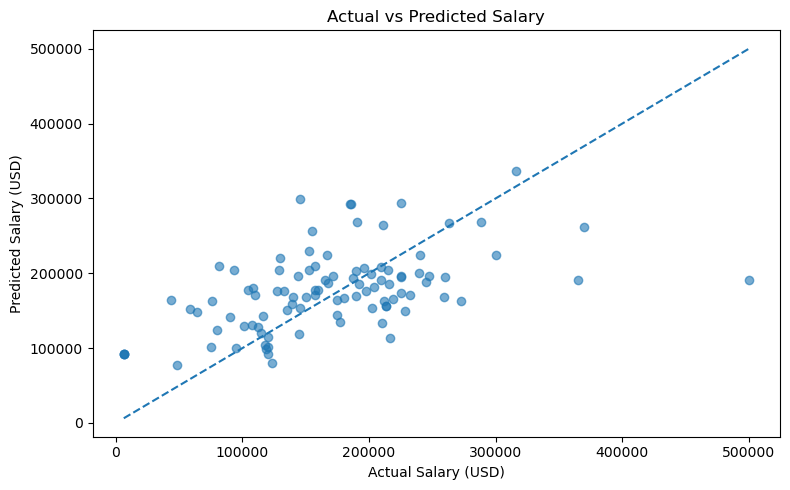

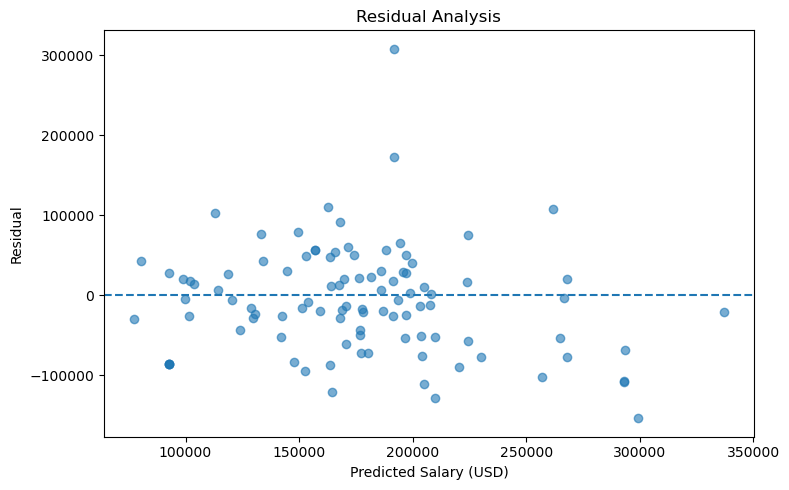


========== TOP FEATURES ==========


,Feature,Importance
30,numerical__Experience_Years_Extracted,0.322747
31,numerical__Skill_Count,0.237974
22,categorical__Job_Industry_Sales,0.060332
9,categorical__Job_Industry_Cybersecurity,0.046890
23,categorical__Job_Industry_Software Engineering,0.041104
1,categorical__Job_Level_Standardized_Leadership,0.037604
4,categorical__Job_Level_Standardized_Senior,0.036937
3,categorical__Job_Level_Standardized_Other,0.031160
27,categorical__Employment_Type_Standardized_Full...,0.025230
18,categorical__Job_Industry_Product & Operations,0.022445


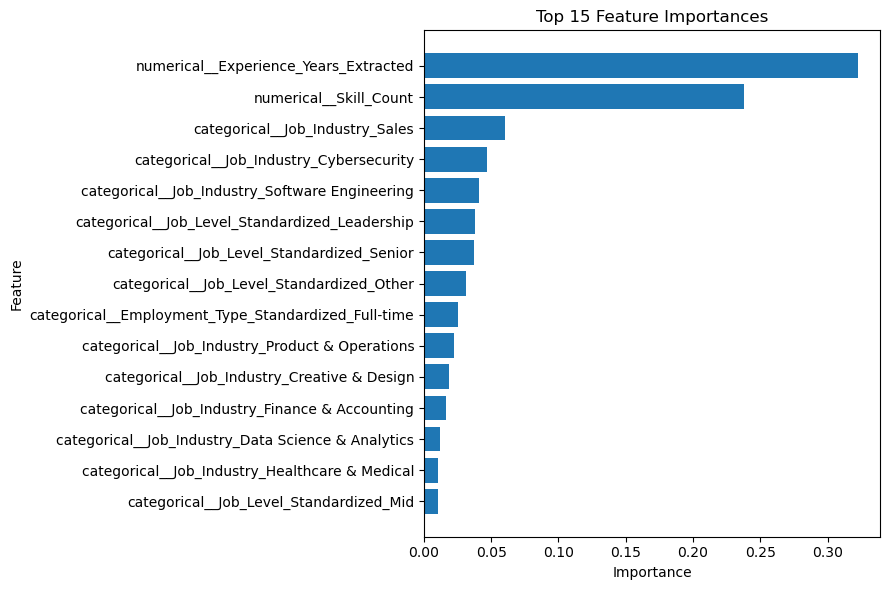


========== 5-FOLD CROSS-VALIDATION ==========
R² Scores: [ 0.2526  0.0122  0.0483 -0.5047  0.0419]
Mean CV R²: -0.0299
Std CV R² : 0.2523

========== FINAL ML SUMMARY ==========
Algorithm: Random Forest Regression
Target: Annual_Salary_USD
Training Records: 394
Testing Records: 99
RMSE: 68289.4
MAE: 51715.36
Test R²: 0.2493
Mean CV R²: -0.0299


In [4]:

# ============================================================
# TASK 4: MACHINE LEARNING MODEL
# Random Forest Regression for Salary Prediction
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

# Use only records having standardized USD salary
model_df = df.dropna(subset=["Annual_Salary_USD"]).copy()

print("Total records available for ML:", len(model_df))

# ------------------------------------------------------------
# 2. SELECT FEATURES
# ------------------------------------------------------------

features = [
    "Experience_Years_Extracted",
    "Skill_Count",
    "Job_Level_Standardized",
    "Job_Industry",
    "Employment_Type_Standardized"
]

X = model_df[features].copy()

# Target variable
y = model_df["Annual_Salary_USD"].copy()

# Handle missing experience values
X["Experience_Years_Extracted"] = X["Experience_Years_Extracted"].fillna(
    X["Experience_Years_Extracted"].median()
)

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# ------------------------------------------------------------
# 4. PREPROCESSING
# ------------------------------------------------------------

categorical_cols = [
    "Job_Level_Standardized",
    "Job_Industry",
    "Employment_Type_Standardized"
]

numerical_cols = [
    "Experience_Years_Extracted",
    "Skill_Count"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numerical",
            "passthrough",
            numerical_cols
        )
    ]
)

# ------------------------------------------------------------
# 5. RANDOM FOREST MODEL
# ------------------------------------------------------------

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", rf_model)
])

# ------------------------------------------------------------
# 6. TRAIN MODEL
# ------------------------------------------------------------

pipeline.fit(X_train, y_train)

# Predictions
y_pred = pipeline.predict(X_test)

print("\nModel training completed.")

# ------------------------------------------------------------
# 7. MODEL PERFORMANCE
# ------------------------------------------------------------

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n========== MODEL PERFORMANCE ==========")
print("Model : Random Forest Regressor")
print("RMSE  :", round(rmse, 2))
print("MAE   :", round(mae, 2))
print("R²    :", round(r2, 4))

# Performance table
performance = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R² Score"],
    "Value": [
        round(rmse, 2),
        round(mae, 2),
        round(r2, 4)
    ]
})

display(performance)

# ------------------------------------------------------------
# 8. ACTUAL VS PREDICTED SALARY
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Salary (USD)")
plt.ylabel("Predicted Salary (USD)")
plt.title("Actual vs Predicted Salary")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. RESIDUAL ANALYSIS
# ------------------------------------------------------------

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Salary (USD)")
plt.ylabel("Residual")
plt.title("Residual Analysis")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. FEATURE IMPORTANCE
# ------------------------------------------------------------

# Get transformed feature names
feature_names = pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = pipeline.named_steps[
    "model"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n========== TOP FEATURES ==========")
display(feature_importance.head(15))

# Plot top 15 features
plt.figure(figsize=(9, 6))

top_features = feature_importance.head(15).sort_values(
    "Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. CROSS-VALIDATION
# ------------------------------------------------------------

cv_scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("\n========== 5-FOLD CROSS-VALIDATION ==========")
print("R² Scores:", np.round(cv_scores, 4))
print("Mean CV R²:", round(cv_scores.mean(), 4))
print("Std CV R² :", round(cv_scores.std(), 4))

# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n========== FINAL ML SUMMARY ==========")
print("Algorithm: Random Forest Regression")
print("Target: Annual_Salary_USD")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("Test R²:", round(r2, 4))
print("Mean CV R²:", round(cv_scores.mean(), 4))

In [31]:
df.to_csv("cleaned_job_market_data.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Cleaned dataset saved successfully!
Rows: 1021
Columns: 61
